In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import warnings
warnings.simplefilter("ignore", UserWarning)

In [24]:
from plot_utils import (
    plot_loss_acc,
    plot_train_val_loss_acc_separately,
    plot_loss_acc_difference,
    plot_var_acc_legends,
    plot_similar_indices
)

from utils import (
    random_p_data,
    concat_ckpt_metrics,
    create_influences_dict,
    top_last_influences,
    create_inf_int_distances,
    create_inter_entropies,
    create_inner_entropies,
    calc_pairwise_euclideans,
    calc_dist_inf_to_others,
    calc_volumes,
    pairwise_similarity,
    top_inf_indices
)

sys.path.append("../src")
sys.path.append("..")
from src.utils import load_checkpoint

In [4]:
import torch
import os
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm
import numpy as np
import torch.nn.functional as F

from torchvision import datasets, transforms
import torch.nn as nn
from torch.utils.data import Subset, Dataset
from datasets import load_dataset

In [5]:
dir_data="../data/"
dir_tensors = os.path.join("../influences", "sst2")
dir_ckpt = "../checkpoint/"
dir_subset = os.path.join(dir_data,"subset_indices")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
checkpoint_labels =  list([3, 6, 10, 13, 16, 20, 25, 40, 60, 80, 100])
epochs_range = range(1, num_epochs + 1)

In [6]:
class SST2EmbedDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = embeddings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        embedding = torch.tensor(self.embeddings[idx])
        label = torch.tensor(self.labels[idx])
        return embedding, label

In [7]:
sst2_dataset = load_dataset("SetFit/sst2")
subset_indices = torch.load(f"{dir_subset}/sst2_embed_train_subset_indices.pt")
EMBEDDING_TRAIN_SST2 = "../data/sst-2/embedding_train.pt"
sst2_train_embeddings = torch.load(EMBEDDING_TRAIN_SST2)
sst2_embed_train_dataset = SST2EmbedDataset(sst2_train_embeddings, sst2_dataset['train']['label'])
sst2_embed_train_subset = Subset(sst2_embed_train_dataset, subset_indices)


Repo card metadata block was not found. Setting CardData to empty.


In [8]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

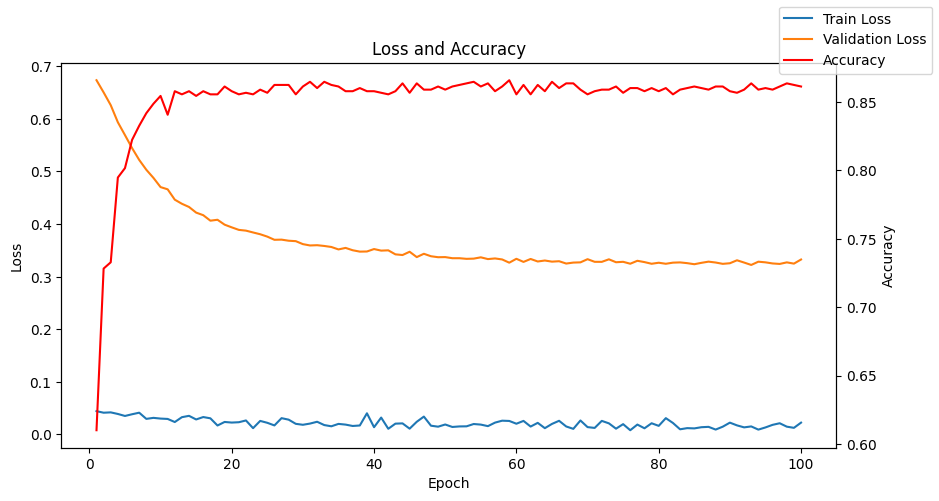

In [9]:
plot_loss_acc(epochs_range, train_losses, validation_losses, accuracies)

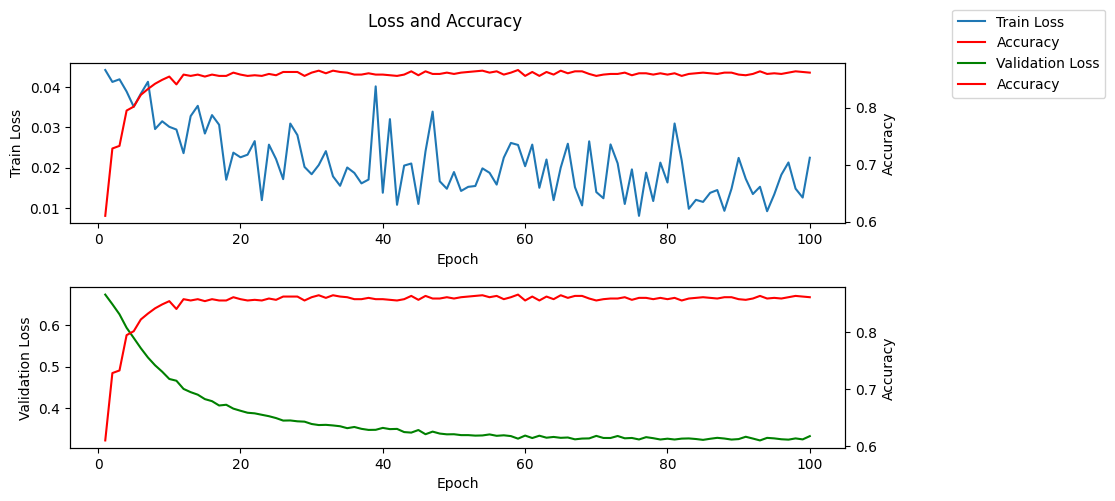

In [10]:
plot_train_val_loss_acc_separately(epochs_range, train_losses, validation_losses, accuracies)

# Influences

In [11]:
x_vals =  list(range(1, num_epochs+1))
num_data = len(sst2_embed_train_subset)
checkpoints_filepaths = [os.path.join(dir_ckpt, "TextCNN", f"TextCNN_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

sst2_influences_if = save_objs_dict["sst2_influences_if"]
sst2_influences_tracin = save_objs_dict["sst2_influences_tracin"]
validate_dict, rand_dict = create_influences_dict(save_objs_dict, checkpoint_labels)

In [12]:
scoring_methods = ["if", "tracin"]
influences_methods = [sst2_influences_if, sst2_influences_tracin]

embeds_dict =  {}
for i in range(len(scoring_methods)):
    the_random_embeds = random_p_data(influences_methods[i], sst2_embed_train_subset, num_data, p) 
    the_random_embeds_large = random_p_data(influences_methods[i], sst2_embed_train_subset, num_data, p*10)
    the_last_ckpts_embeds = top_last_influences(influences_methods[i], sst2_embed_train_subset, int(p*num_data), False) 
    the_top_ckpts_embeds = top_last_influences(influences_methods[i], sst2_embed_train_subset, int(num_data*p))
    
    embeds_dict[scoring_methods[i]] = {
        "random": the_random_embeds, 
        "random_large": the_random_embeds_large, 
        "last": the_last_ckpts_embeds, 
        "top": the_top_ckpts_embeds}

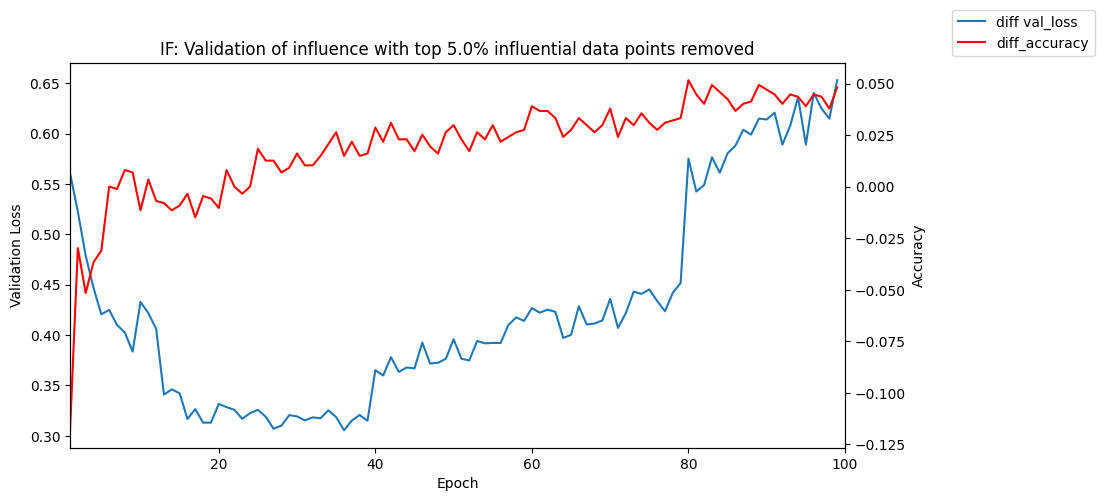

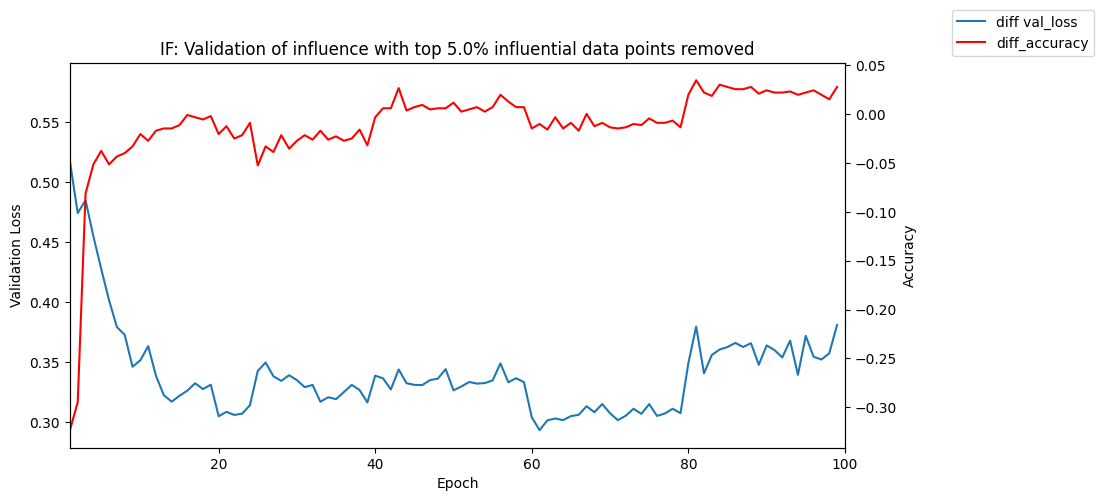

In [13]:
for scoring_method in scoring_methods:
    diff_val_loss = concat_ckpt_metrics(validate_dict[f"validate_validation_losses_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(rand_dict[f"rand_validate_train_losses_{scoring_method}"], checkpoint_labels) # suppose positive
    diff_accuracy = concat_ckpt_metrics(rand_dict[f"rand_validate_accuracies_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(validate_dict[f"validate_accuracies_{scoring_method}"], checkpoint_labels) # suppose positive
    plot_loss_acc_difference(diff_val_loss, diff_accuracy, scoring_method="IF", p=p)

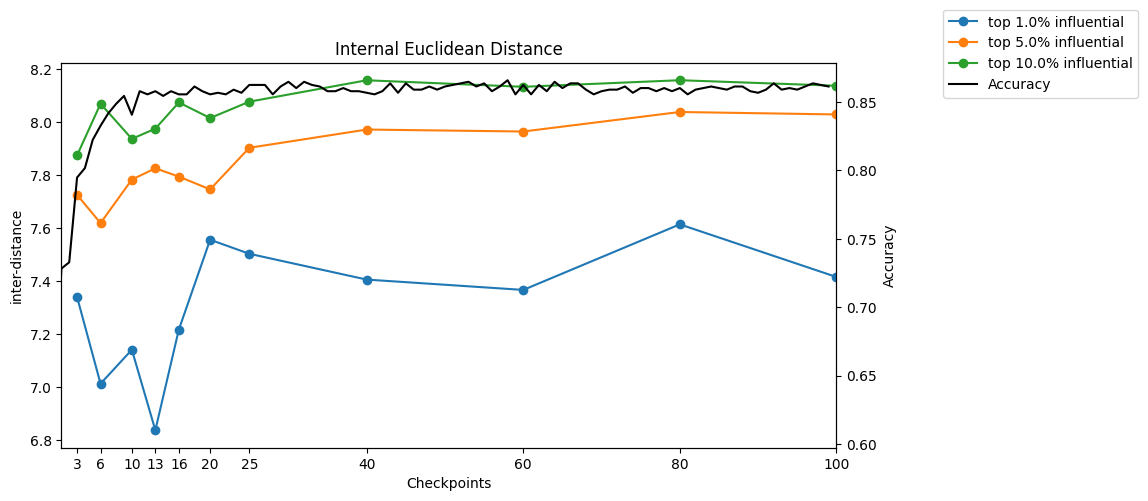

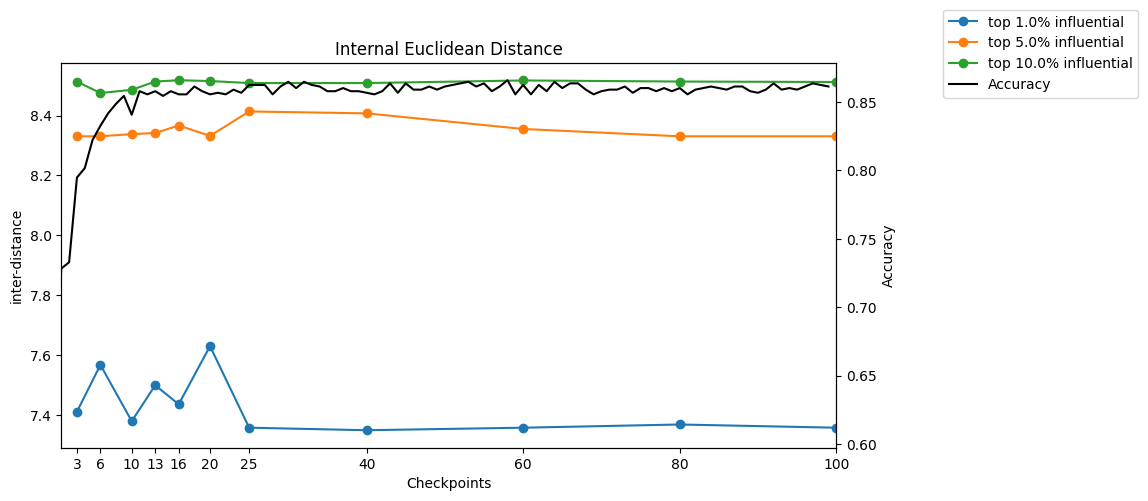

In [14]:
ls_p = [0.01, 0.05, 0.1]

for sst2_influences in influences_methods:
    ls_int_distances = calc_pairwise_euclideans(sst2_influences, sst2_embed_train_subset, list_p=ls_p)
    kwargs = {
        "title": "Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": ls_int_distances,
        "legend_labels": [f"top {prob*100}% influential" for prob in ls_p]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

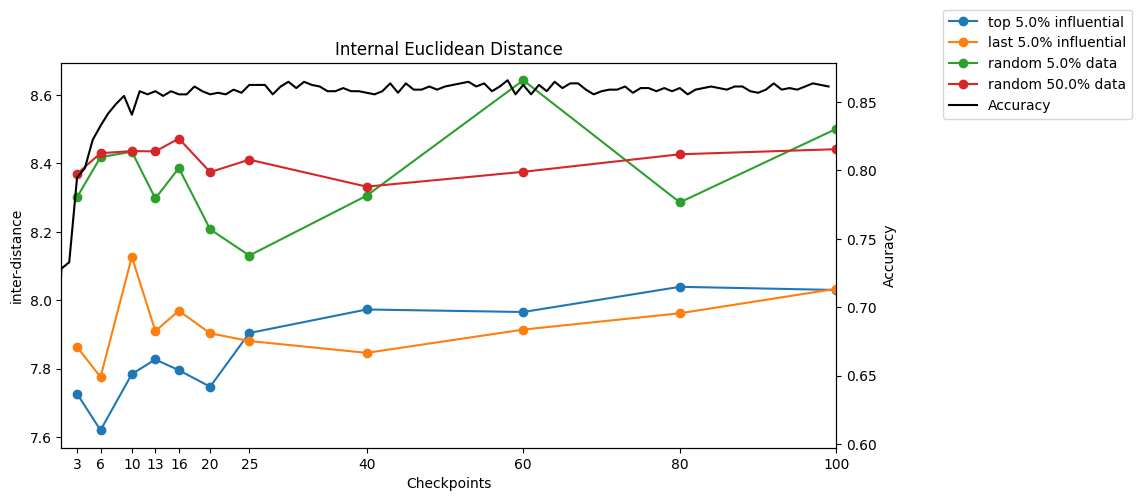

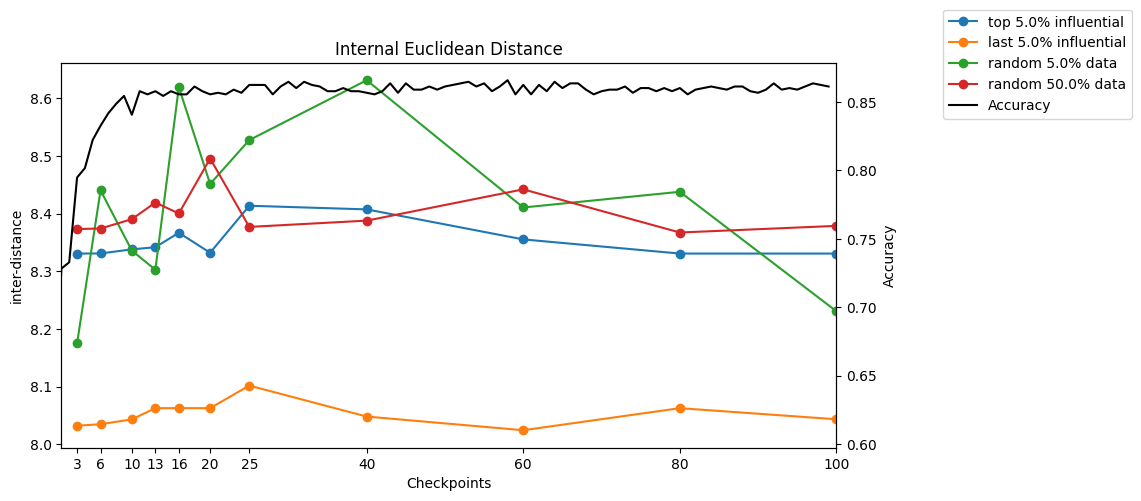

In [15]:
p = 0.05
for i in range(len(scoring_methods)):
    topinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["top"])
    lastinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["last"])
    rand_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["random"])
    randlarge_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["random_large"])

    kwargs = {
        "title": "Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": [topinf_int_distances, lastinf_int_distances, rand_int_distances, randlarge_int_distances],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

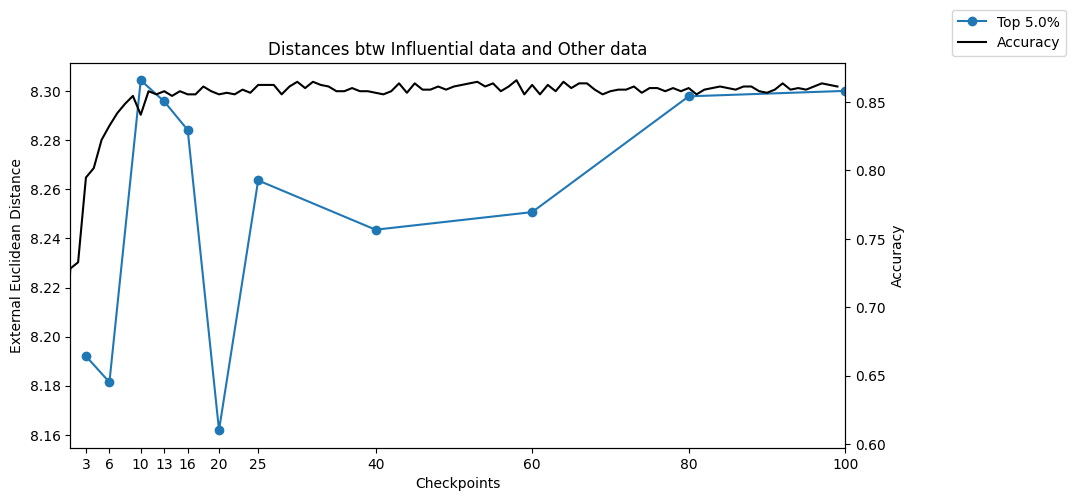

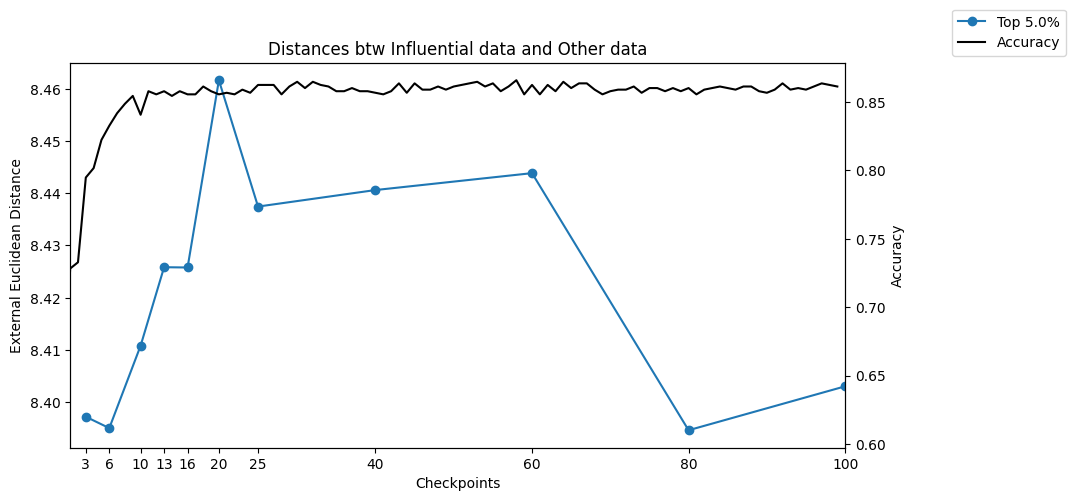

In [16]:
# Euclidean distance from influential points to other points
for i in range(len(scoring_methods)):
    distances = calc_dist_inf_to_others(select_inf_embeds = embeds_dict[scoring_methods[i]]["top"], 
                                        other_inf_embeds = embeds_dict[scoring_methods[i]]["random_large"])

    kwargs = {
        "title": "Distances btw Influential data and Other data",
        "y_label": "External Euclidean Distance",
        "data": [distances],
        "legend_labels": [f"Top {p*100}%"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)


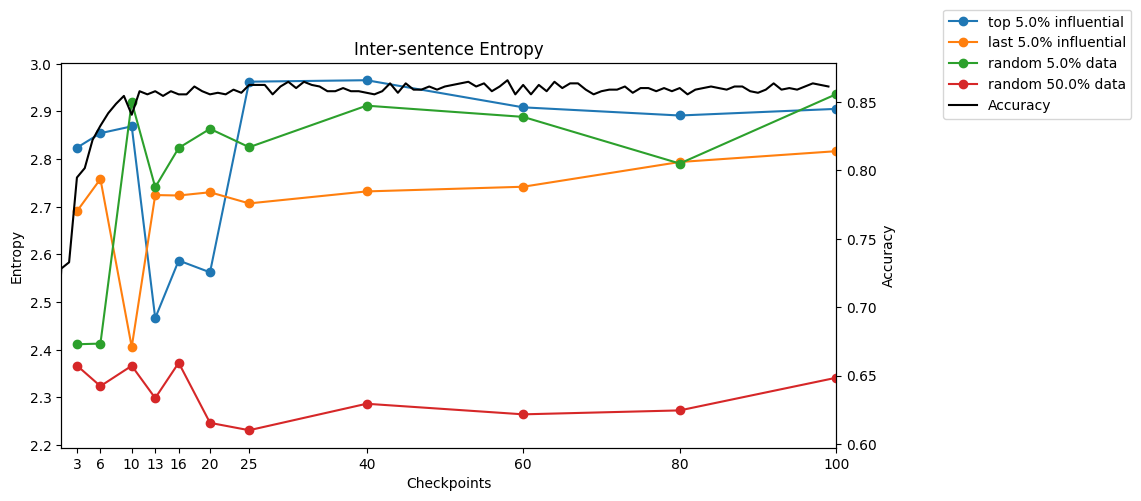

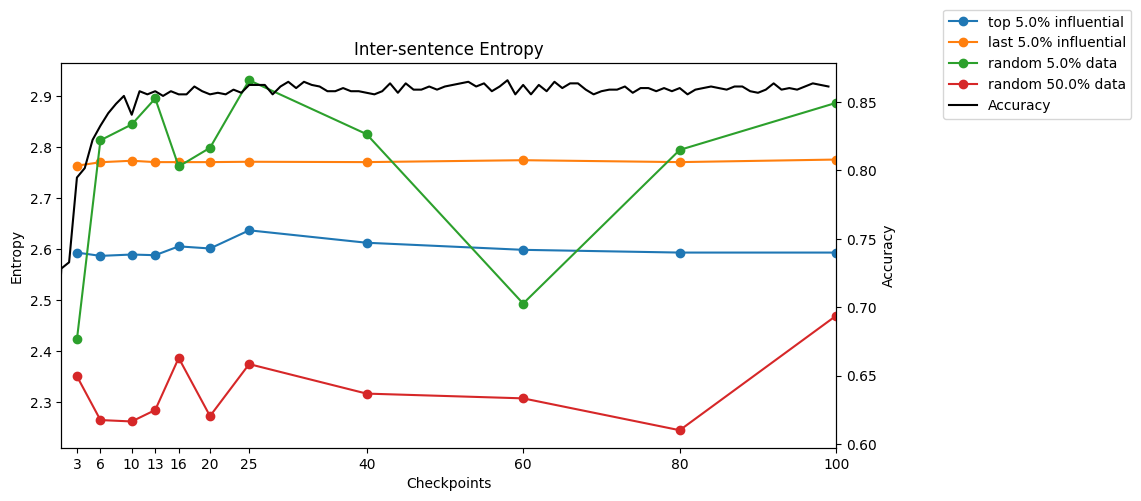

In [17]:
for i in range(len(scoring_methods)):
    topinf_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["top"])
    lastinf_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["last"])
    rand_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["random"])
    rand_pw_large_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["random_large"])
    
    kwargs = {
        "title": "Inter-sentence Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies, rand_pw_large_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

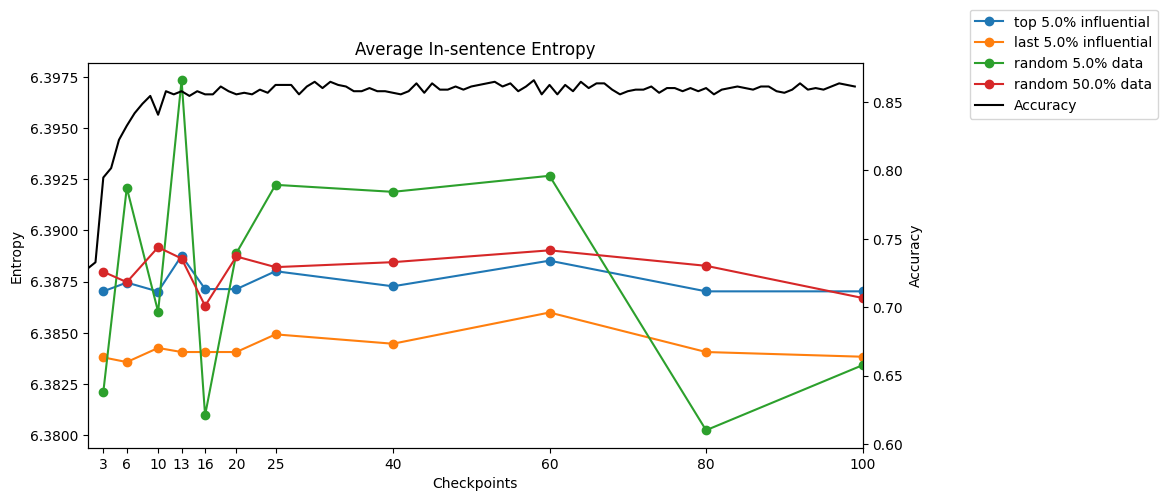

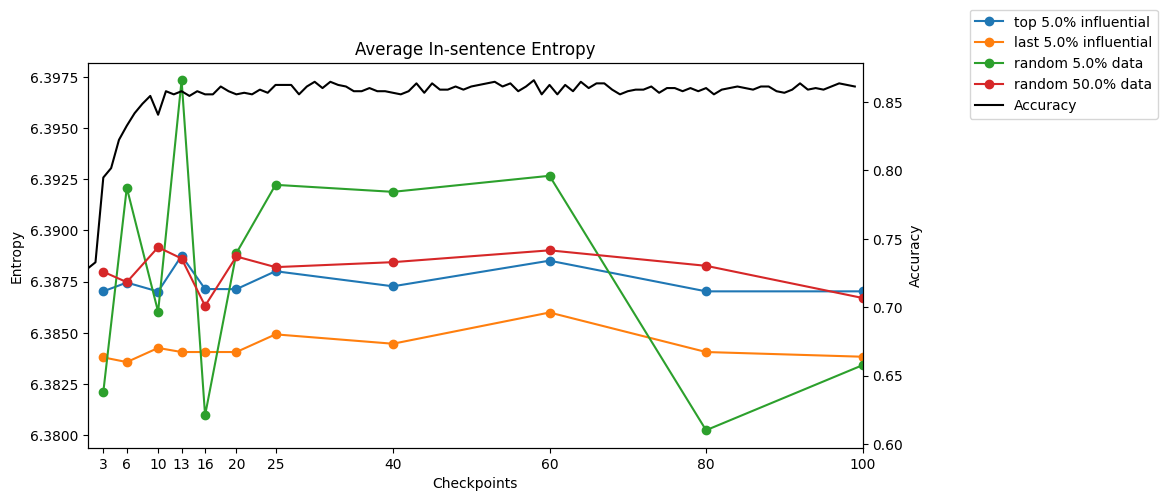

In [18]:
for r in range(len(scoring_methods)):
    topinf_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["top"])
    lastinf_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["last"])
    rand_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["random"])
    rand_pw_large_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["random_large"])

    kwargs = {
        "title": "Average In-sentence Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies, rand_pw_large_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

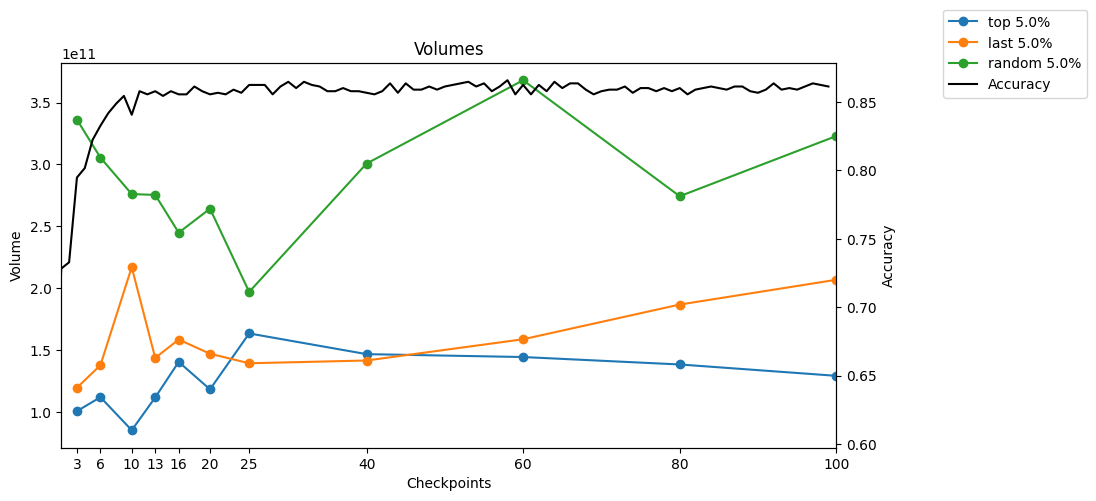

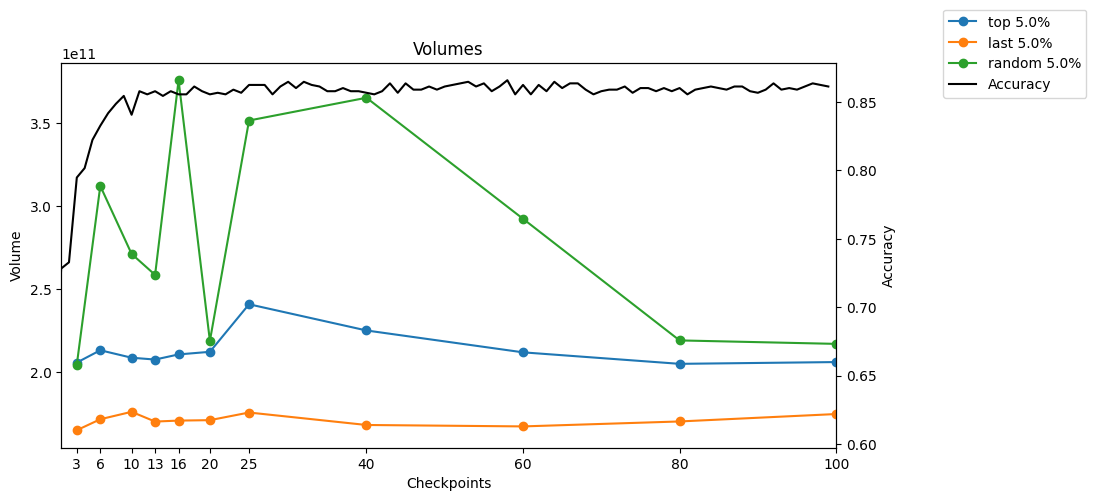

In [19]:
labels = ["top", "last", "random"]

for i in range(len(scoring_methods)):
    ls_volumes = calc_volumes([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["last"], embeds_dict[scoring_methods[i]]["random"]])
    kwargs = {
        "title": "Volumes",
        "y_label": "Volume",
        "data": ls_volumes,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

# Retrain on Top n IP

In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cuda


In [21]:
class TextCNN(nn.Module):
    def __init__(self, embed_dim=768, num_classes=2, kernel_sizes=[2, 3, 4], num_filters=2):
        super(TextCNN, self).__init__()
        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embed_dim)) for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(len(kernel_sizes) * num_filters, num_classes)
        
    def forward(self, x):
        conv_outputs = []
        for conv in self.convs:
            conv_output = F.relu(conv(x)) # [batch size, num_filters, seq_len - kernel_size + 1, 1]
            conv_output_pool = F.max_pool2d(conv_output, (conv_output.shape[2], 1))
            conv_outputs.append(conv_output_pool.squeeze(3).squeeze(2))
        output = torch.cat(conv_outputs, dim=1)
        output = self.dropout(output)
        output = self.fc(output)
        return output

    def to(self, device):
        super().to(device)
        self.device = device
        return self

torch.Size([78, 768])
Checkpoint loaded at epoch 3 with completion rate 0.03
torch.Size([78, 768])
Checkpoint loaded at epoch 6 with completion rate 0.06
torch.Size([78, 768])
Checkpoint loaded at epoch 10 with completion rate 0.1
torch.Size([78, 768])
Checkpoint loaded at epoch 13 with completion rate 0.13
torch.Size([78, 768])
Checkpoint loaded at epoch 16 with completion rate 0.16
torch.Size([78, 768])
Checkpoint loaded at epoch 20 with completion rate 0.2
torch.Size([78, 768])
Checkpoint loaded at epoch 25 with completion rate 0.25
torch.Size([78, 768])
Checkpoint loaded at epoch 40 with completion rate 0.4
torch.Size([78, 768])
Checkpoint loaded at epoch 60 with completion rate 0.6
torch.Size([78, 768])
Checkpoint loaded at epoch 80 with completion rate 0.8
torch.Size([78, 768])
Checkpoint loaded at epoch 100 with completion rate 1.0
torch.Size([78, 768])
Checkpoint loaded at epoch 3 with completion rate 0.03
torch.Size([78, 768])
Checkpoint loaded at epoch 6 with completion rate 

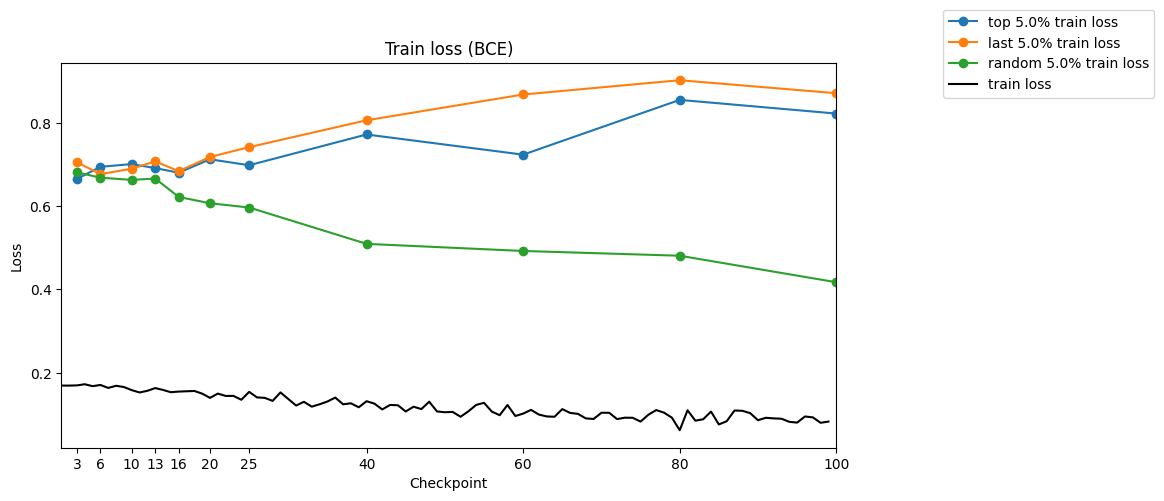

In [23]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    train_losses = [] # CrossEntropy loss
    for i, embeds in enumerate(ckpts_embeds):
        print(embeds[0][0].shape)
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device).unsqueeze(1)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        optimizer = torch.optim.Adam(TextCNN().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
        loss_fn = nn.CrossEntropyLoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
             label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = torch.load("../influences/sst2/sst2_train_losses.pt")
ax1.plot(train_losses, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

In [26]:
accuracies

[tensor(0.6000, device='cuda:0'),
 tensor(0.5600, device='cuda:0'),
 tensor(0.4600, device='cuda:0'),
 tensor(0.4500, device='cuda:0'),
 tensor(0.5200, device='cuda:0'),
 tensor(0.4600, device='cuda:0'),
 tensor(0.5700, device='cuda:0'),
 tensor(0.4900, device='cuda:0'),
 tensor(0.5700, device='cuda:0'),
 tensor(0.4500, device='cuda:0'),
 tensor(0.5500, device='cuda:0')]

Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 6 with completion rate 0.06
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 13 with completion rate 0.13
Checkpoint loaded at epoch 16 with completion rate 0.16
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 25 with completion rate 0.25
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 6 with completion rate 0.06
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 13 with completion rate 0.13
Checkpoint loaded at epoch 16 with completion rate 0.16
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 25 with completion rate 0.25
Che

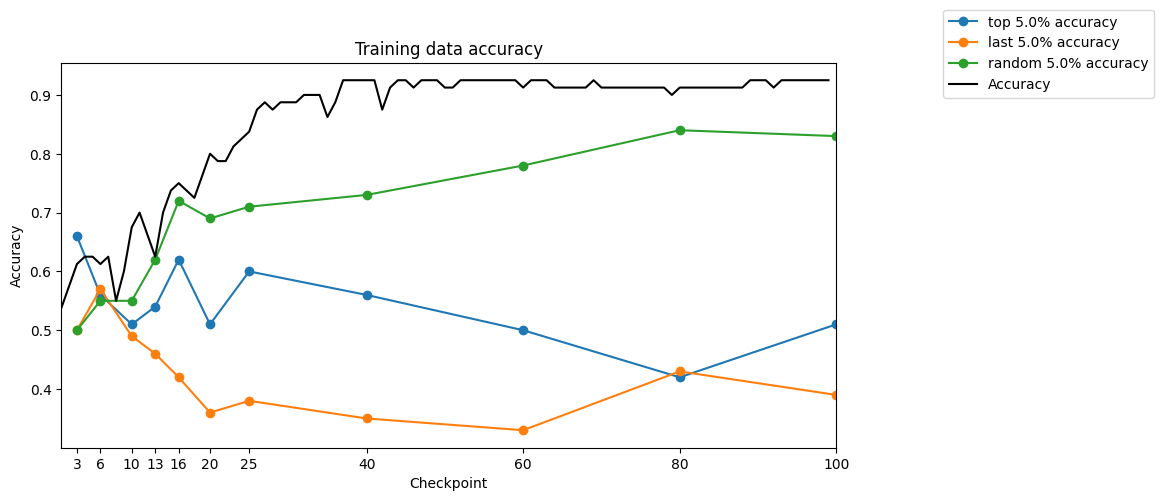

In [27]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device).unsqueeze(1)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=-1)
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy.cpu())
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/sst2/sst2_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

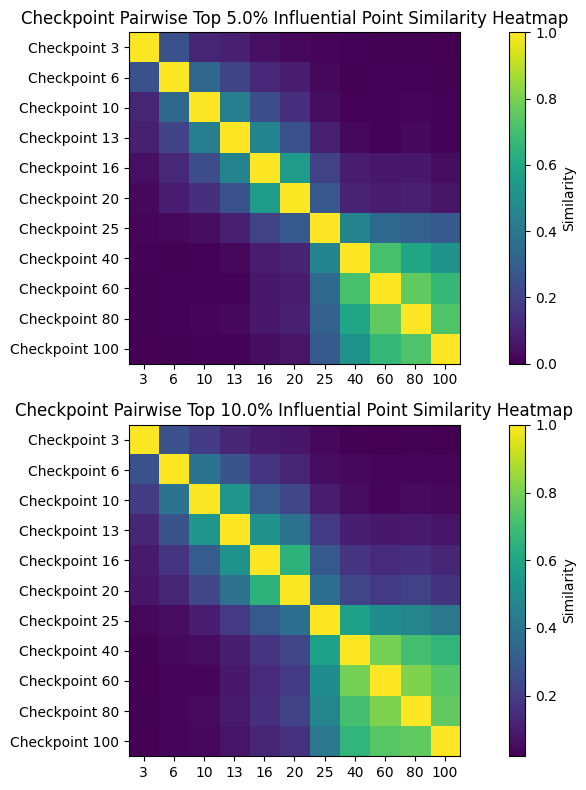

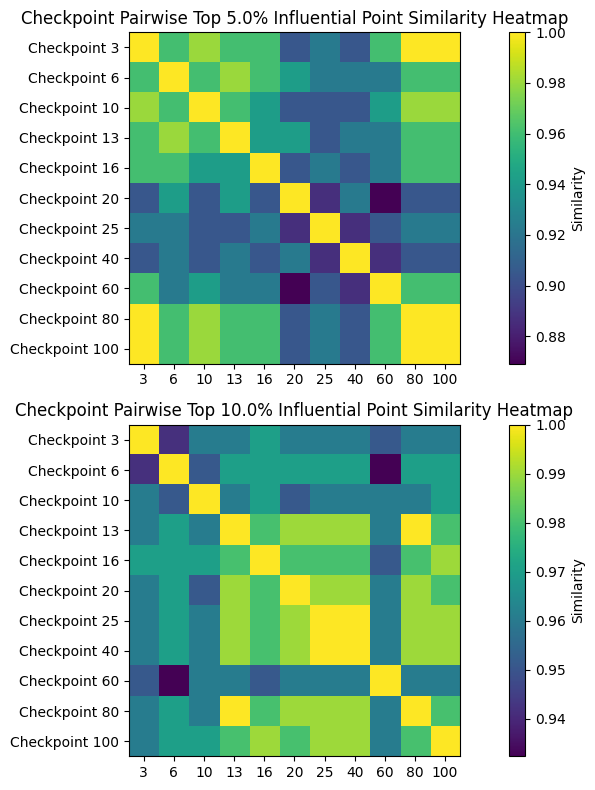

In [28]:
for i in range(len(scoring_methods)):
    pw_similarities_lowp = pairwise_similarity(top_inf_indices(influences_methods[i], int(p*num_data)))
    pw_similarities_highp = pairwise_similarity(top_inf_indices(influences_methods[i], int(0.1*num_data)))

    plot_similar_indices(pw_similarities_lowp, pw_similarities_highp, checkpoint_labels, p)